# Telecom Customer Churn Analysis

**Business question:** Which telecom customers are likely to leave, and what drives it?

**Data:** 243,553 customers of four Indian telecom providers (Reliance Jio, Airtel, Vodafone, BSNL), with demographics, location, registration date, usage (calls, SMS, data) and whether the customer churned.

## Summary of findings

1. **About 1 in 5 customers churned (20.05%).** The rate is almost identical across providers, genders, cities and registration months.
2. **No feature is meaningfully associated with churn.** Chi-square and Mann-Whitney tests find no practically significant relationship, and every correlation with churn is close to zero.
3. **The models cannot beat a coin flip.** All three models score a ROC-AUC of about 0.50, which is what random guessing gives. Their precision equals the base churn rate (~20%).
4. **Accuracy is misleading here.** A model that predicts "nobody churns" is 80% accurate. The Random Forest in my first version reached 79.95% accuracy by doing almost exactly that, and caught zero churners.
5. **The data looks synthetic.** Values are uniformly distributed, and city does not match state (for example, customers in Karnataka with Kolkata as their city).

**Conclusion:** This dataset does not contain the signals needed to predict churn, so no model built on it should be used for decisions. To predict churn, the business would need data such as contract type, tenure, plan price, complaints and network quality.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
RANDOM_STATE = 42

## 2. Load the data

In [2]:
df = pd.read_csv("telecom_churn.csv", parse_dates=["date_of_registration"])
print(df.shape)
df.head()

(243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   customer_id           243553 non-null  int64         
 1   telecom_partner       243553 non-null  object        
 2   gender                243553 non-null  object        
 3   age                   243553 non-null  int64         
 4   state                 243553 non-null  object        
 5   city                  243553 non-null  object        
 6   pincode               243553 non-null  int64         
 7   date_of_registration  243553 non-null  datetime64[ns]
 8   num_dependents        243553 non-null  int64         
 9   estimated_salary      243553 non-null  int64         
 10  calls_made            243553 non-null  int64         
 11  sms_sent              243553 non-null  int64         
 12  data_used             243553 non-null  int64         
 13 

In [4]:
df.describe()

,customer_id,age,pincode,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000
mean,121777.000000,46.077609,549501.270541,1.997500,85021.137839,49.010548,23.945404,4993.186025,0.200478
std,70307.839393,16.444029,259808.860574,1.414941,37508.963233,29.453556,14.733575,2942.019547,0.400359
min,1.000000,18.000000,100006.000000,0.000000,20000.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,60889.000000,32.000000,324586.000000,1.000000,52585.000000,24.000000,11.000000,2490.000000,0.000000
50%,121777.000000,46.000000,548112.000000,2.000000,84990.000000,49.000000,24.000000,4987.000000,0.000000
75%,182665.000000,60.000000,774994.000000,3.000000,117488.000000,74.000000,36.000000,7493.000000,0.000000
max,243553.000000,74.000000,999987.000000,4.000000,149999.000000,108.000000,53.000000,10991.000000,1.000000


## 3. Data quality checks

Before analysing anything, I check whether the data can be trusted: missing values, duplicates, impossible values, and whether related fields agree with each other.

In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
df.nunique()

Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0


customer_id             243553
telecom_partner              4
gender                       2
age                         57
state                       28
city                         6
pincode                 213442
date_of_registration      1220
num_dependents               5
estimated_salary        110032
calls_made                 119
sms_sent                    59
data_used                11837
churn                        2
dtype: int64

### 3.1 Impossible negative usage values

Calls, SMS and data used cannot be negative. I mark these as missing here, and fill them later **inside the model pipeline using the training-set median only**, so no information from the test set leaks into training.

In [6]:
usage_cols = ["calls_made", "sms_sent", "data_used"]
for col in usage_cols:
    n_neg = (df[col] < 0).sum()
    print(f"{col}: {n_neg:,} negative values ({n_neg / len(df):.2%})")
    df.loc[df[col] < 0, col] = np.nan

calls_made: 6,713 negative values (2.76%)
sms_sent: 7,375 negative values (3.03%)
data_used: 6,050 negative values (2.48%)


### 3.2 Does city match state?

Each customer has both a state and a city. If the data is real, a customer in Kolkata should be in West Bengal.

In [7]:
city_state = {"Kolkata": "West Bengal", "Mumbai": "Maharashtra", "Chennai": "Tamil Nadu",
              "Bangalore": "Karnataka", "Hyderabad": "Telangana", "Delhi": None}  # Delhi is not in the state list

checkable = df[df["city"].isin([c for c, s in city_state.items() if s])]
matches = (checkable["state"] == checkable["city"].map(city_state)).mean()
print(f"Customers whose state matches their city: {matches:.1%}")
pd.crosstab(df["state"], df["city"]).head(8)

Customers whose state matches their city: 3.6%


city,Bangalore,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
state,,,,,,
Andhra Pradesh,1476,1425,1441,1459,1429,1419
Arunachal Pradesh,1473,1498,1450,1447,1419,1470
Assam,1391,1461,1468,1391,1433,1403
Bihar,1491,1437,1448,1372,1441,1444
Chhattisgarh,1450,1456,1409,1446,1509,1407
Goa,1464,1479,1436,1426,1436,1453
Gujarat,1406,1478,1399,1469,1428,1430
Haryana,1467,1471,1421,1401,1485,1495


Only a few percent of customers have a state that matches their city, which is roughly what random assignment across 28 states would give. Real customer records would match almost every time. **This strongly suggests the dataset is synthetic**, which matters for everything that follows: patterns found here may not exist in real customer behaviour.

### 3.3 Registration dates

In [8]:
monthly_counts = df["date_of_registration"].dt.to_period("M").value_counts().sort_index()
print("First registration:", df["date_of_registration"].min().date())
print("Last registration: ", df["date_of_registration"].max().date())
print("Customers in the last month:", monthly_counts.iloc[-1], "vs typical month:", int(monthly_counts.median()))

First registration: 2020-01-01
Last registration:  2023-05-04
Customers in the last month: 600 vs typical month: 6193


The final month contains only a few days of registrations, so I leave it out of the monthly trend to avoid a false drop.

## 4. Exploratory analysis

### 4.1 Churn rate overall and by segment

I compare **churn rates**, not raw counts. Counts only show which group is bigger; rates show whether a group is more likely to leave.

Overall churn rate: 20.05%  (48,827 of 243,553 customers)


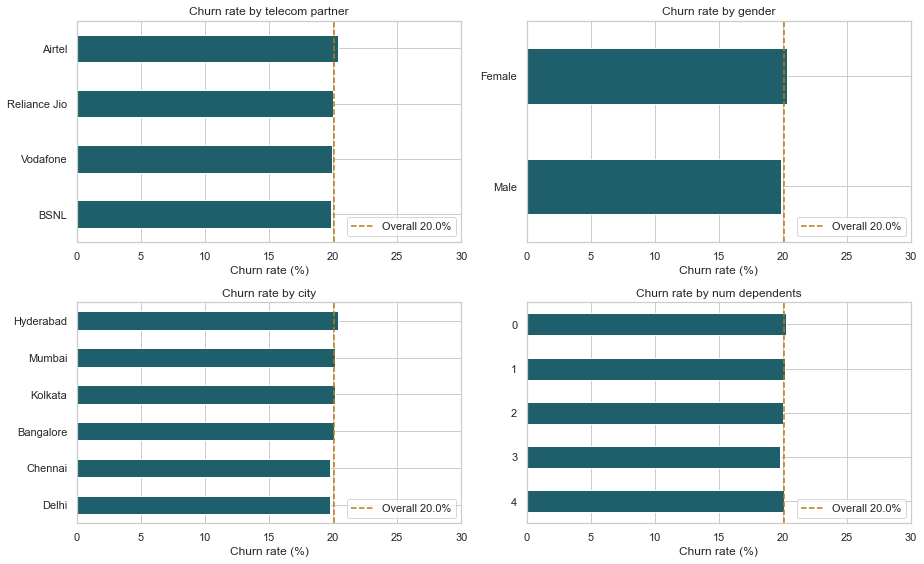

In [9]:
overall_rate = df["churn"].mean()
print(f"Overall churn rate: {overall_rate:.2%}  ({df['churn'].sum():,} of {len(df):,} customers)")

segments = ["telecom_partner", "gender", "city", "num_dependents"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), segments):
    rates = df.groupby(col)["churn"].mean() * 100
    rates = rates.sort_index(ascending=False) if col == "num_dependents" else rates.sort_values()
    if col == "gender":
        rates.index = rates.index.map({"M": "Male", "F": "Female"})
    rates.plot.barh(ax=ax, color="#1F5F6B", label="_nolegend_")
    ax.axvline(overall_rate * 100, color="#B87A12", linestyle="--", label=f"Overall {overall_rate:.1%}")
    ax.set_xlim(0, 30)
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    ax.set_title(f"Churn rate by {col.replace('_', ' ')}")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/churn_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

Every segment sits within about one percentage point of the overall 20% churn rate. Men and women, all four providers, all six cities and every family size churn at nearly the same rate.

### 4.2 Usage and demographics: churned vs stayed

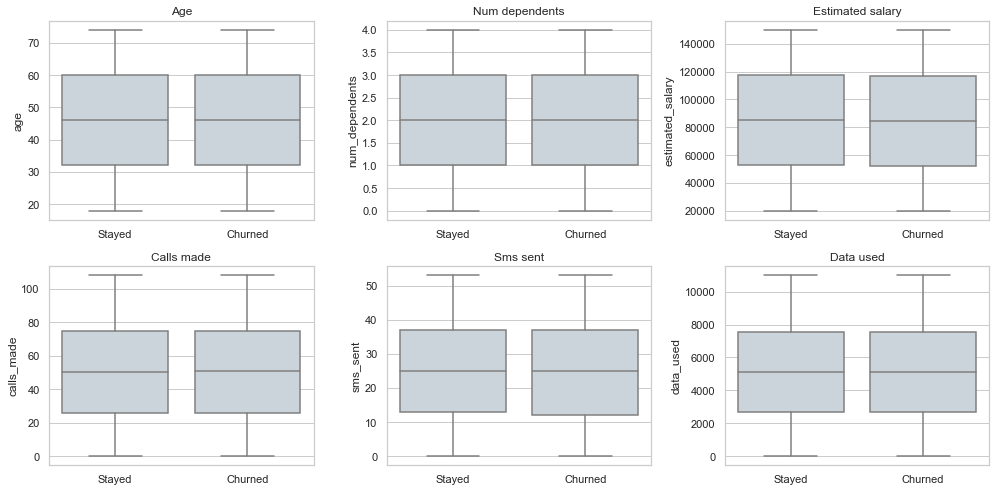

In [10]:
numeric_cols = ["age", "num_dependents", "estimated_salary", "calls_made", "sms_sent", "data_used"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(data=df, x="churn", y=col, ax=ax, color="#C9D4DC")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Stayed", "Churned"])
    ax.set_xlabel("")
    ax.set_title(col.replace("_", " ").capitalize())
plt.tight_layout()
plt.show()

The distributions for customers who stayed and customers who churned are almost identical for every variable.

### 4.3 Distributions

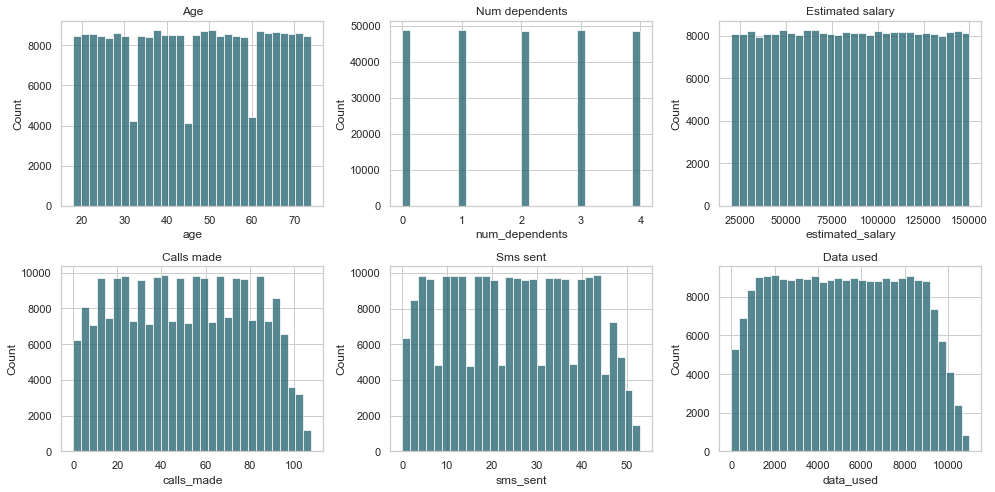

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df[col].dropna(), bins=30, ax=ax, color="#1F5F6B")
    ax.set_title(col.replace("_", " ").capitalize())
plt.tight_layout()
plt.show()

All variables are close to uniformly distributed (flat), and there are no outliers by the IQR rule. Real-world salary and usage data is usually skewed, with a long tail of heavy users and high earners. This is a second sign the data is synthetic.

### 4.4 Correlation

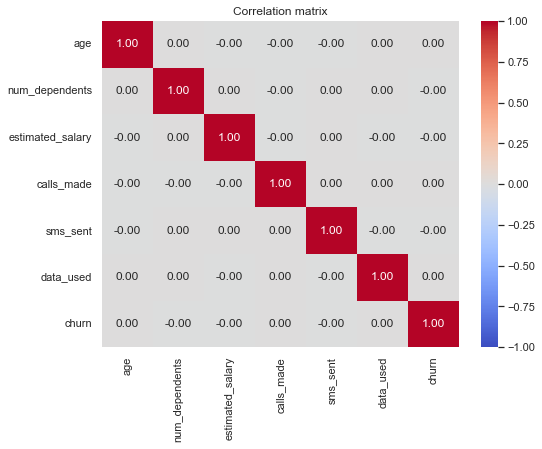

estimated_salary   -0.0033
num_dependents     -0.0025
sms_sent           -0.0022
age                 0.0008
data_used           0.0016
calls_made          0.0022
Name: churn, dtype: float64

In [12]:
corr = df[numeric_cols + ["churn"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()
corr["churn"].drop("churn").round(4).sort_values()

## 5. Statistical tests

Charts can mislead, so I test each feature formally:
- **Categorical features:** chi-square test of independence, with Cramér's V to measure the strength of the association (0 = none, 1 = perfect).
- **Numeric features:** Mann-Whitney U test comparing customers who churned with those who stayed (no normality assumption).

With 243,000 rows, even tiny, meaningless differences can be "statistically significant", so I look at effect size as well as the p-value.

In [13]:
results = []
for col in ["telecom_partner", "gender", "state", "city", "num_dependents"]:
    table = pd.crosstab(df[col], df["churn"])
    chi2, p, dof, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    results.append({"feature": col, "test": "Chi-square", "p_value": p, "effect_size": cramers_v})

for col in ["age", "estimated_salary", "calls_made", "sms_sent", "data_used"]:
    stayed = df.loc[df["churn"] == 0, col].dropna()
    churned = df.loc[df["churn"] == 1, col].dropna()
    u, p = mannwhitneyu(stayed, churned)
    rank_biserial = 1 - 2 * u / (len(stayed) * len(churned))
    results.append({"feature": col, "test": "Mann-Whitney U", "p_value": p, "effect_size": abs(rank_biserial)})

tests = pd.DataFrame(results).sort_values("effect_size", ascending=False)
tests["meaningful?"] = np.where(tests["effect_size"] >= 0.1, "Yes", "No")
tests.round(4)

,feature,test,p_value,effect_size,meaningful?
2,state,Chi-square,0.5624,0.0102,No
3,city,Chi-square,0.1320,0.0059,No
1,gender,Chi-square,0.0122,0.0051,No
6,estimated_salary,Mann-Whitney U,0.1003,0.0048,No
0,telecom_partner,Chi-square,0.1332,0.0048,No
4,num_dependents,Chi-square,0.5139,0.0037,No
7,calls_made,Mann-Whitney U,0.2578,0.0034,No
8,sms_sent,Mann-Whitney U,0.2811,0.0032,No
9,data_used,Mann-Whitney U,0.4326,0.0023,No
5,age,Mann-Whitney U,0.6788,0.0012,No


Effect sizes below 0.1 are considered negligible. No feature comes close, so none of them meaningfully separates customers who churn from those who stay.

## 6. Monthly churn trend

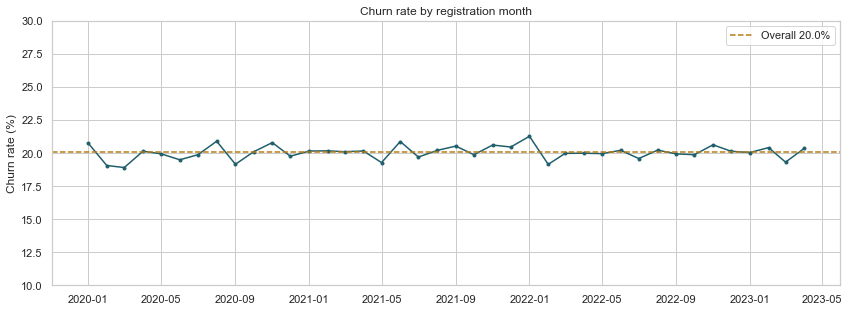

Monthly churn rate ranges from 18.9% to 21.3%


In [14]:
monthly = (df.assign(month=df["date_of_registration"].dt.to_period("M"))
             .groupby("month")["churn"].agg(customers="count", churn_rate="mean"))
monthly = monthly.iloc[:-1]                      # drop the partial final month
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly["churn_rate"] * 100, color="#1F5F6B", marker="o", markersize=3)
ax.axhline(overall_rate * 100, color="#B87A12", linestyle="--", label=f"Overall {overall_rate:.1%}")
ax.set_ylim(10, 30)
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by registration month")
ax.legend()
plt.tight_layout()
plt.savefig("images/monthly_churn_rate.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Monthly churn rate ranges from {monthly['churn_rate'].min():.1%} to {monthly['churn_rate'].max():.1%}")

On a 0–30% scale, monthly churn is flat: it moves about a percentage point either side of 20%, with no upward or downward trend. The month-to-month "peaks and drops" are random noise.

## 7. Can churn be predicted?

Even though the analysis found no clear drivers, I test whether a model can find a combination of features that predicts churn.

**Approach**
- **Features:** demographics, location, usage, and `tenure_days` (days since registration). I drop `customer_id` and `pincode`, which are identifiers.
- **Split first, then preprocess.** I split into 80% train and 20% test, stratified by churn. All preprocessing happens in a pipeline fitted on the training data only, so nothing from the test set leaks into training.
- **Encoding:** one-hot encoding for provider, gender, state and city. Label encoding would wrongly tell the model that, say, Kerala > Karnataka.
- **Baselines:** two dummy models, one predicting "never churns" and one guessing at random in proportion to the churn rate. A useful model must beat these.
- **Metric:** ROC-AUC (0.5 = random guessing, 1.0 = perfect), plus recall: of the customers who actually left, how many did the model catch?

In [15]:
reference_date = df["date_of_registration"].max()
df["tenure_days"] = (reference_date - df["date_of_registration"]).dt.days

categorical_features = ["telecom_partner", "gender", "state", "city"]
numeric_features = ["age", "num_dependents", "estimated_salary", "calls_made", "sms_sent", "data_used", "tenure_days"]

X = df[categorical_features + numeric_features]
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows ({y_test.sum():,} churners)")

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", MinMaxScaler())]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

Train: 194,842 rows | Test: 48,711 rows (9,765 churners)


In [16]:
models = {
    "Baseline: always 'stays'": DummyClassifier(strategy="most_frequent"),
    "Baseline: random guess": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=50, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
}

rows, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

scores = pd.DataFrame(rows).set_index("model")
scores.style.format("{:.3f}").background_gradient(subset=["roc_auc"], cmap="Greens", vmin=0.5, vmax=0.7)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline: always 'stays',0.800,0.000,0.000,0.000,0.500
Baseline: random guess,0.677,0.195,0.194,0.194,0.496
Logistic Regression,0.505,0.202,0.498,0.287,0.506
Decision Tree,0.422,0.200,0.629,0.304,0.500
Random Forest,0.700,0.202,0.168,0.183,0.503


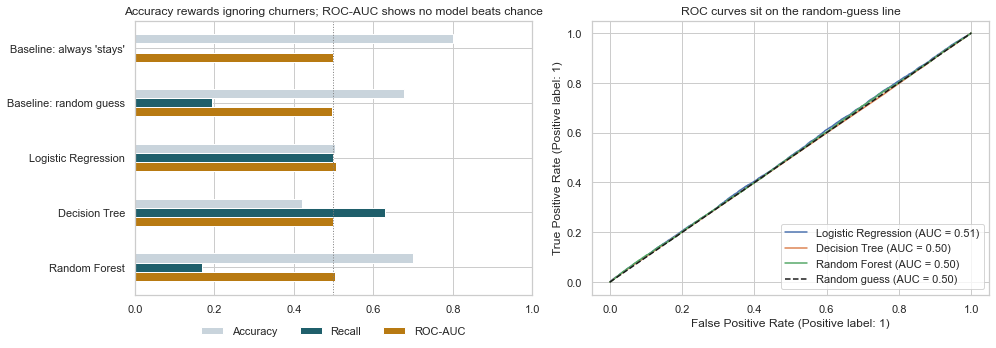

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_scores = scores[["accuracy", "recall", "roc_auc"]]
plot_scores.plot.barh(ax=axes[0], color=["#C9D4DC", "#1F5F6B", "#B87A12"])
axes[0].axvline(0.5, color="grey", linestyle=":", linewidth=1)
axes[0].set_xlim(0, 1)
axes[0].set_title("Accuracy rewards ignoring churners; ROC-AUC shows no model beats chance")
axes[0].set_ylabel("")
axes[0].invert_yaxis()
axes[0].legend(axes[0].containers, ["Accuracy", "Recall", "ROC-AUC"], loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)

for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.50)")
axes[1].legend(loc="lower right")
axes[1].set_title("ROC curves sit on the random-guess line")

plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.1 Is the result stable?

A single train/test split can be lucky or unlucky, so I check Logistic Regression with 5-fold stratified cross-validation on the training data.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(fitted["Logistic Regression"], X_train, y_train, cv=cv, scoring="roc_auc")
print("ROC-AUC per fold:", np.round(cv_auc, 3))
print(f"Mean ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

ROC-AUC per fold: [0.498 0.498 0.498 0.506 0.5  ]
Mean ROC-AUC: 0.500 ± 0.003


### 7.2 Confusion matrices

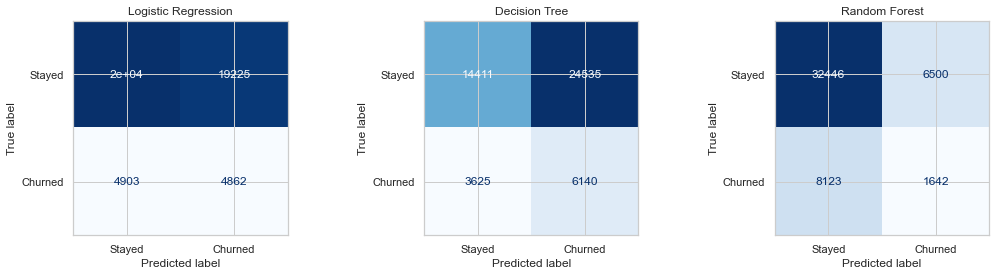

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, ax=ax, cmap="Blues",
                                          display_labels=["Stayed", "Churned"], colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 7.3 What did the Random Forest rely on?

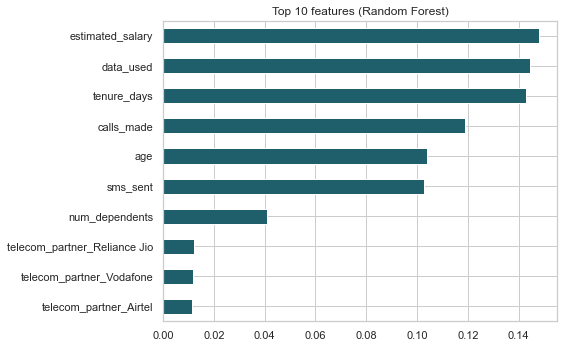

In [20]:
rf = fitted["Random Forest"]
feature_names = rf.named_steps["prep"].get_feature_names_out()
importances = (pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names)
                 .sort_values(ascending=False).head(10))
importances.index = importances.index.str.replace("num__", "").str.replace("cat__", "")
importances.sort_values().plot.barh(figsize=(8, 5), color="#1F5F6B", title="Top 10 features (Random Forest)")
plt.tight_layout()
plt.show()

The "most important" features are the continuous ones (salary, data used, tenure). That is not because they predict churn, but because a tree can split continuous values in many ways. With ROC-AUC at chance level, these importances reflect noise, not real drivers.

## 8. Conclusions

1. **Churn is about 20% and evenly spread.** No provider, city, gender, age group or usage level churns noticeably more than any other.
2. **No feature is associated with churn.** Statistical tests show negligible effect sizes for every variable.
3. **Churn cannot be predicted from this data.** Every model scores a ROC-AUC of about 0.50, the same as random guessing, and cross-validation confirms this is not a fluke of one split.
4. **High accuracy was an illusion.** In my first version of this project, a Random Forest reached 79.95% accuracy while catching none of the 9,765 churners in the test set. It had simply learned to predict "stays" for everyone. Choosing models on recall and ROC-AUC, and comparing them against a dummy baseline, exposes this.
5. **The data appears synthetic.** City and state rarely match, and every variable is uniformly distributed.

## 9. Recommendations

- **Do not deploy a churn model trained on this data.** Its predictions would be no better than chance, and acting on them (for example, sending retention offers) would waste budget.
- **Collect the signals that usually drive telecom churn:** contract type (prepaid or postpaid), plan price and changes, recharge frequency, number-porting requests, complaints and call-centre contacts, and network quality (dropped calls, data speed) by area.
- **Track churn as a rate by cohort and segment** in a dashboard, so changes are visible once richer data is available.

## 10. Limitations

- The dataset appears to be synthetic, so these findings describe this file, not real telecom customers.
- `date_of_registration` is the only time field; there is no churn date, so I cannot analyse when in the customer lifecycle people leave.